
Selected data:
Epoch_number Label Condition  c3_mean_abs   c3_psd  mean_channels_mean_abs  mean_channels_psd  median_channels_mean_abs  median_channels_psd  average_signal_mean_abs  average_signal_psd  c3_mean_abs_bin  c3_psd_bin  mean_channels_mean_abs_bin  mean_channels_psd_bin  median_channels_mean_abs_bin  median_channels_psd_bin  average_signal_mean_abs_bin
       164.0  rest      rest    32.679208 5.457713              127.066465           4.714696                 39.982731             3.572848                19.614166                   8                8           8                           8                      8                             8                        8                            8
       168.0 right  movement     9.630085 2.906280               12.109584           2.886093                 11.402482             2.547179                 9.334598                   5                5           3                           2                      5                   

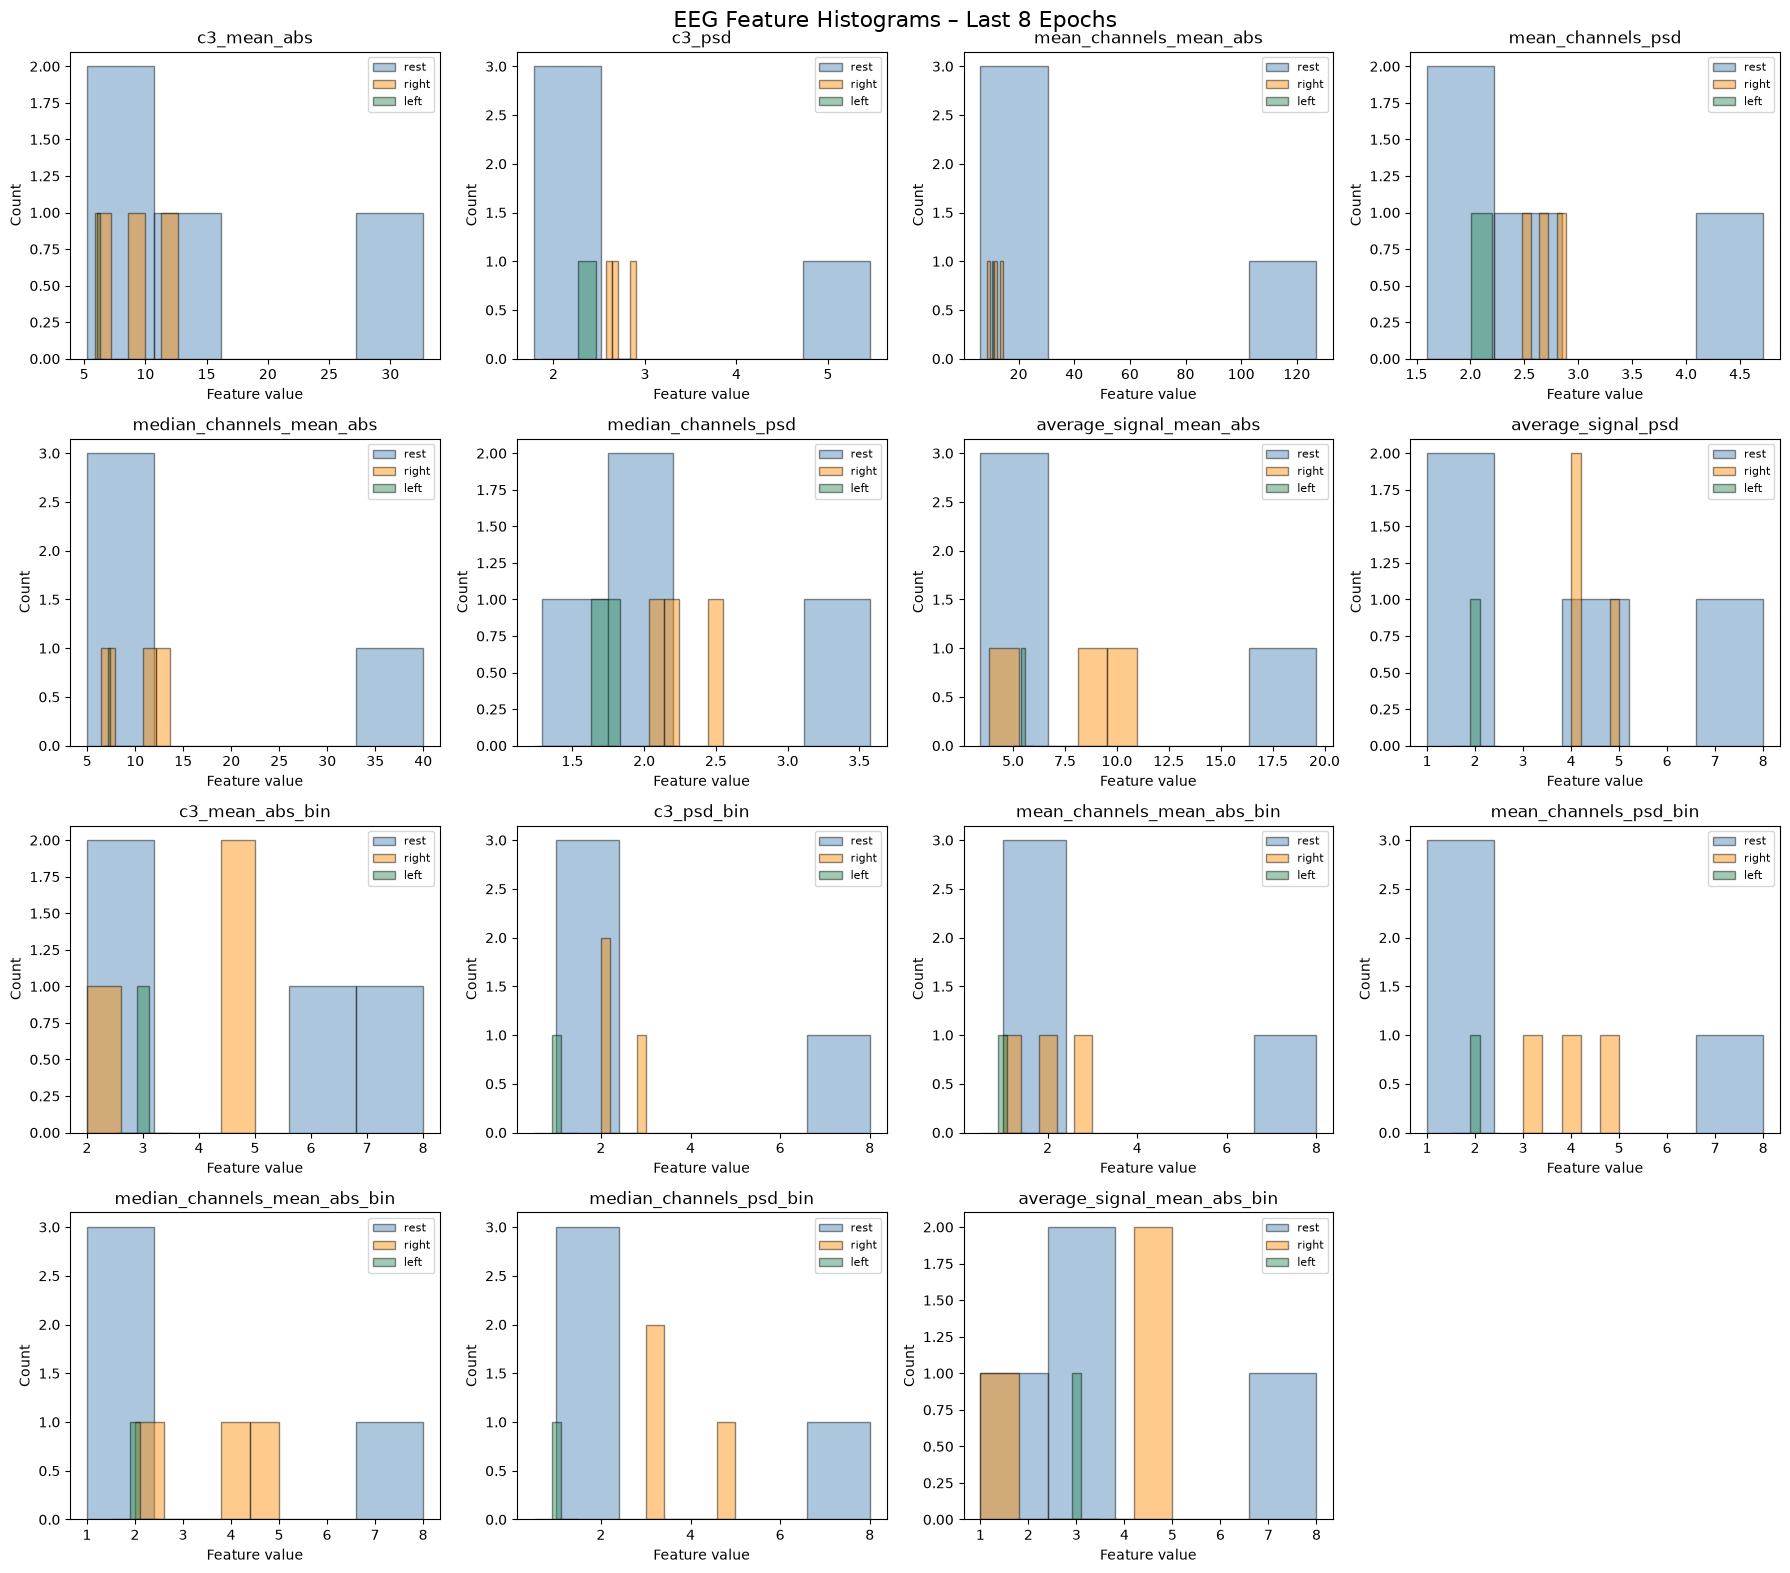

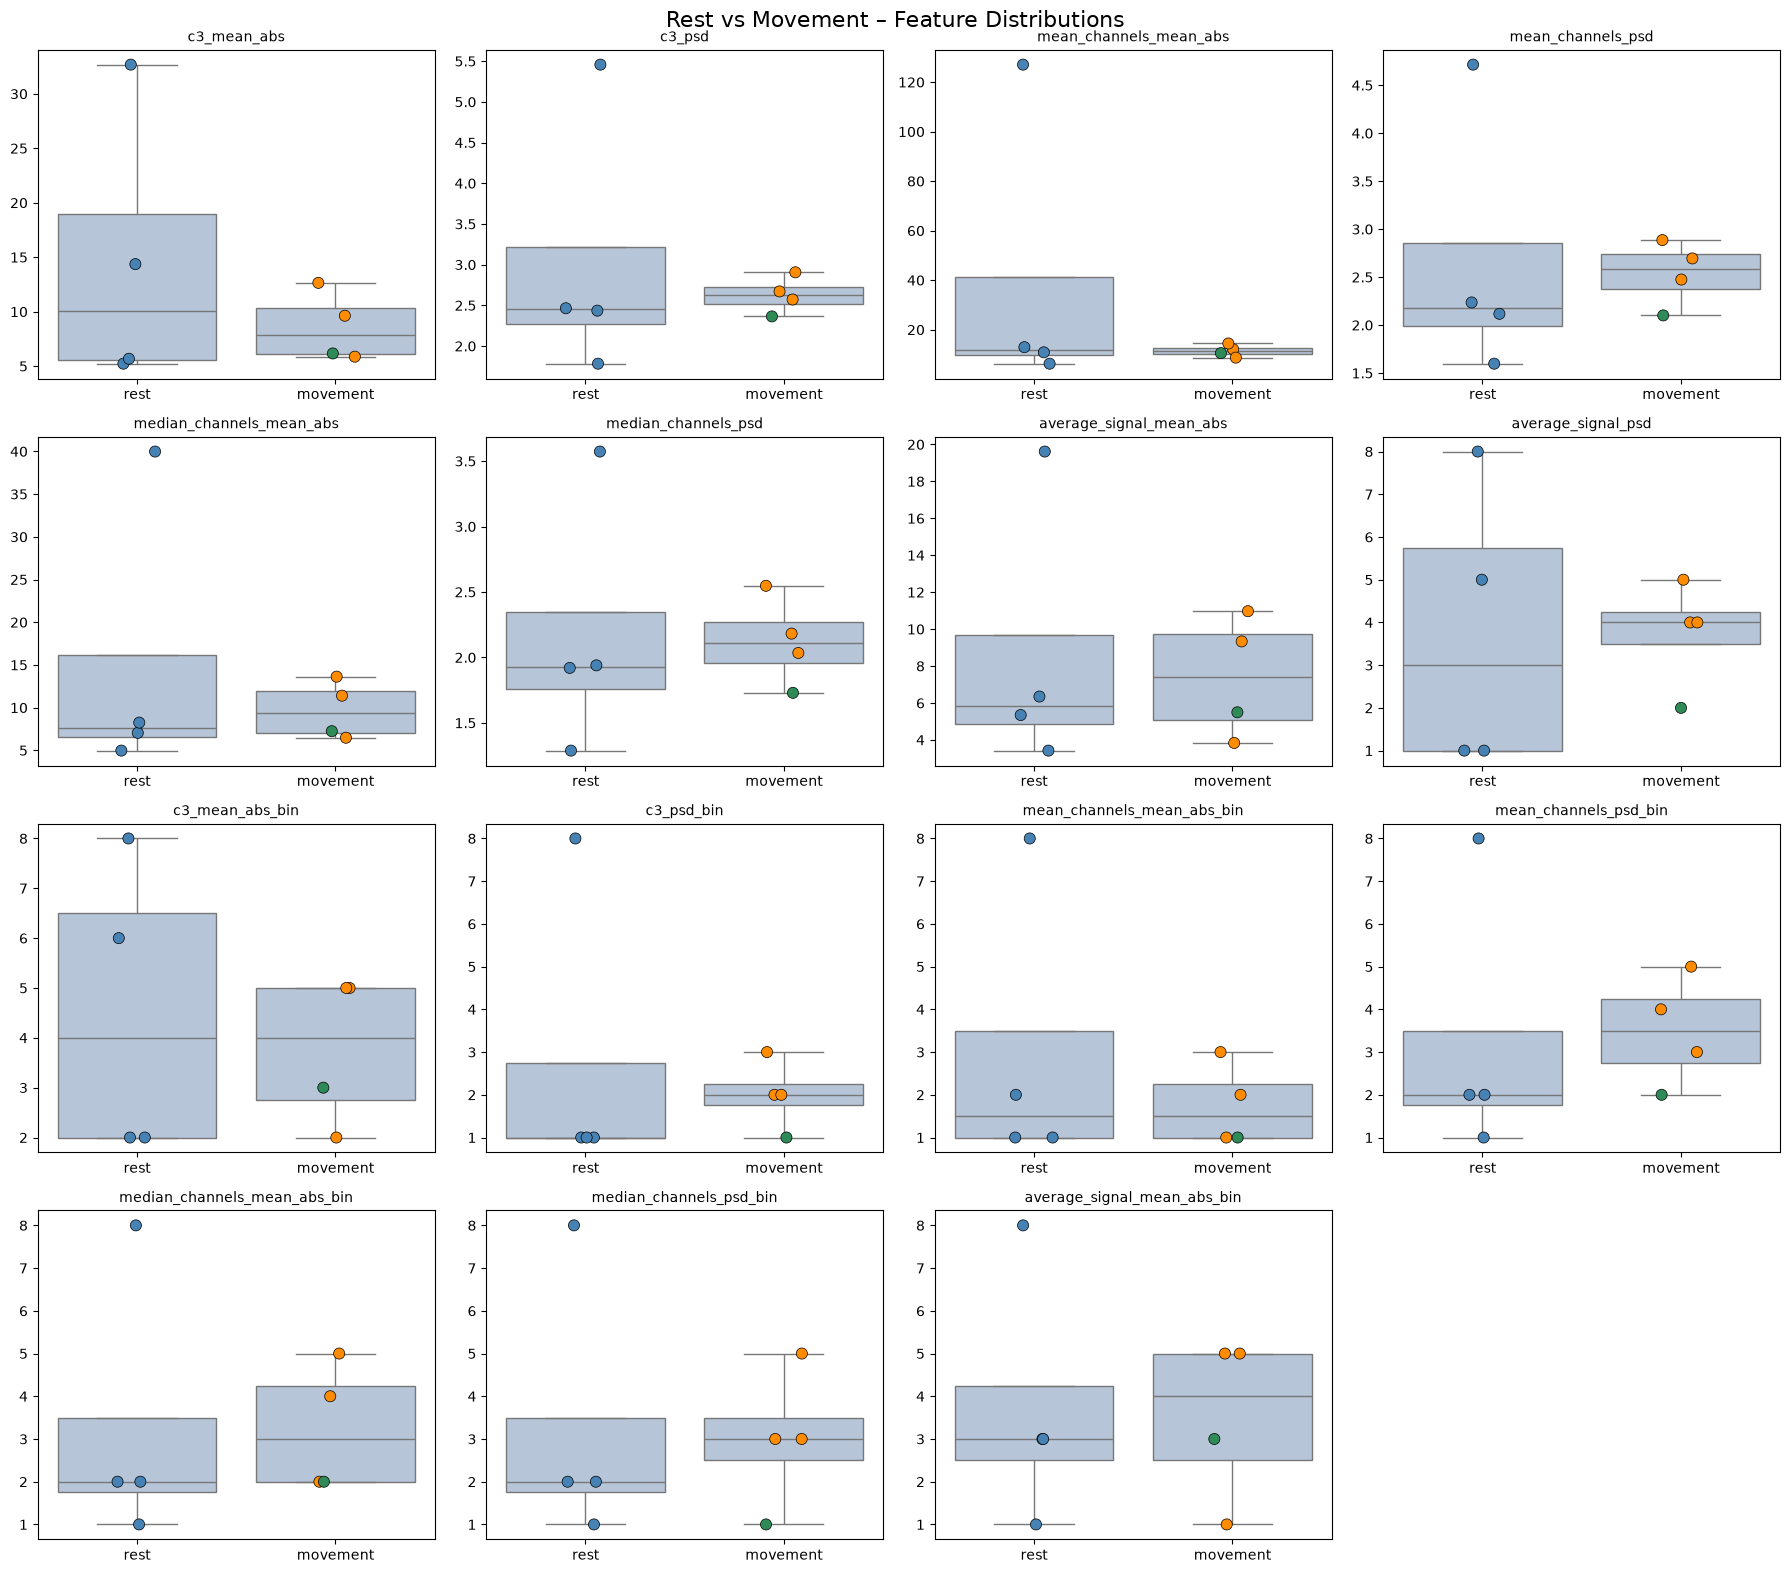

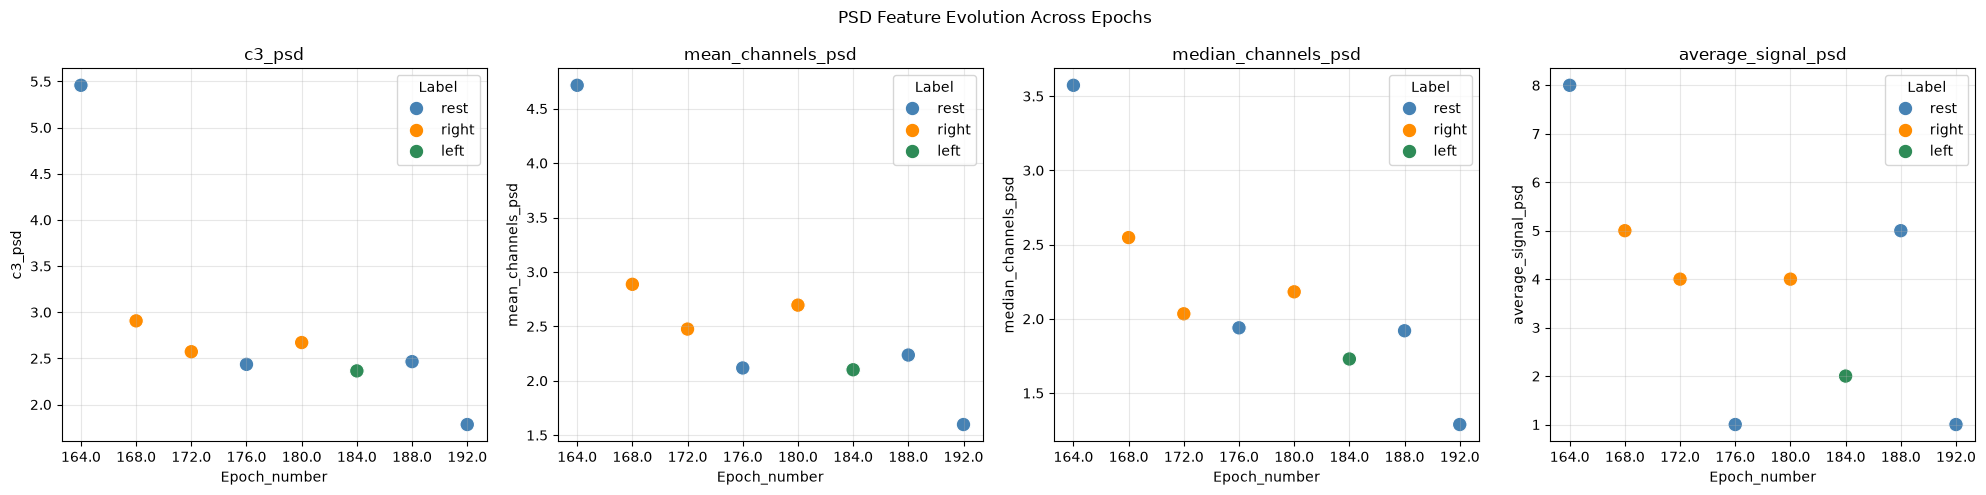


FISHER SCORE RANKING
                     Feature  Rest mean  Movement mean   Rest SD  Movement SD  Fisher score
      mean_channels_mean_abs  39.277652      11.444230 58.592097     2.424588      0.225275
                 c3_mean_abs  14.488674       8.578865 12.835507     3.204068      0.199558
  mean_channels_mean_abs_bin   3.000000       1.750000  3.366502     0.957427      0.127551
    median_channels_mean_abs  15.063484       9.688368 16.667931     3.402591      0.099835
                      c3_psd   3.035174       2.628474  1.645350     0.225073      0.059976
             c3_mean_abs_bin   4.500000       3.750000  3.000000     1.500000      0.050000
                  c3_psd_bin   2.750000       2.000000  3.500000     0.816497      0.043548
     average_signal_mean_abs   8.683739       7.409405  7.387498     3.307017      0.024788
           mean_channels_psd   2.666544       2.539206  1.393302     0.336987      0.007891
       mean_channels_psd_bin   3.250000       3.500000  3.

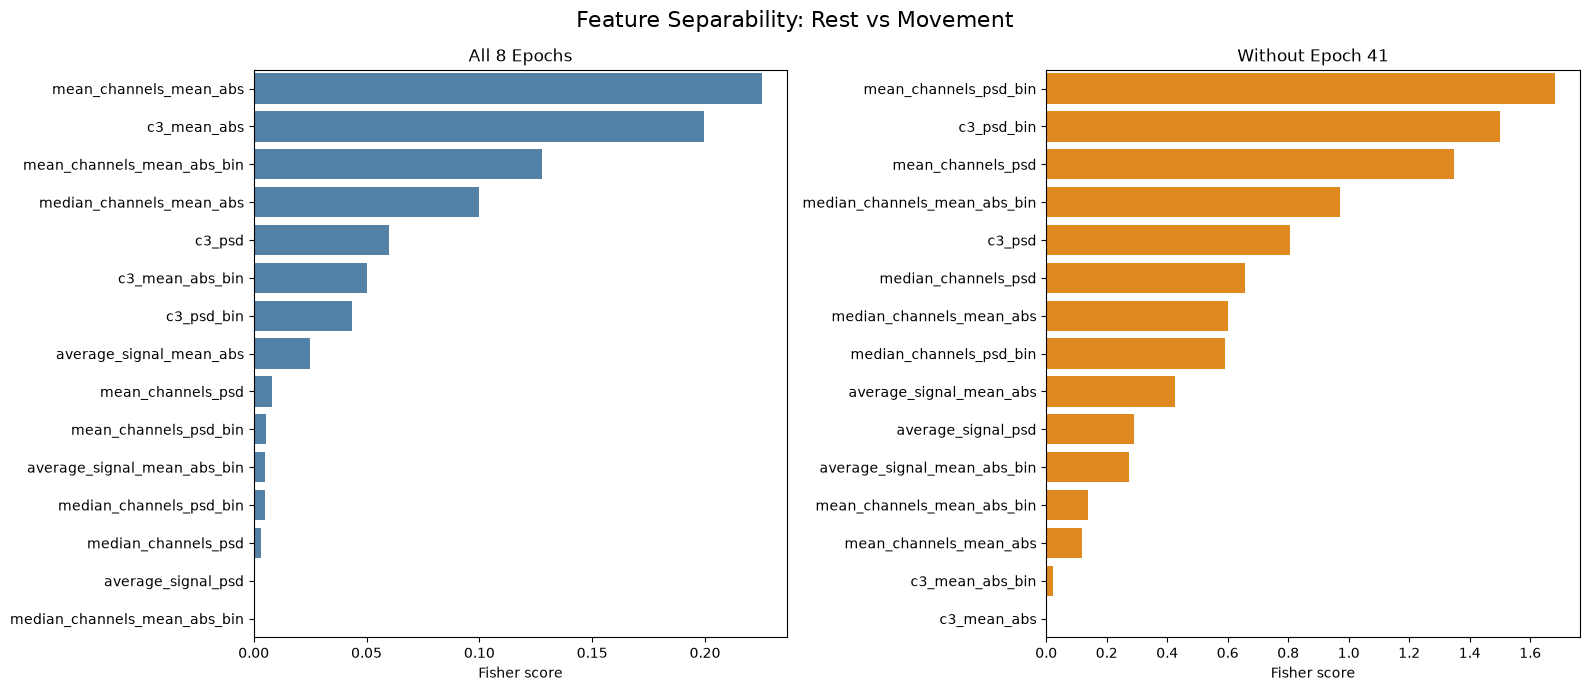


Analysis completed.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import html


df = pd.read_csv("outputs/mu_features.csv")

# Clean column names in case they contain formatting artefacts
df.columns = [
    html.unescape(str(c)).replace("*", "").strip()
    for c in df.columns
]

# Select the last 8 epochs
data = df.tail(8).copy().reset_index(drop=True)

# Experimental labels, chronological order
labels = [
    "rest",
    "right",
    "right",
    "rest",
    "right",
    "left",
    "rest",
    "rest"
]

data["Label"] = labels

# Binary comparison: rest vs movement
data["Condition"] = data["Label"].map({
    "rest": "rest",
    "right": "movement",
    "left": "movement"
})



features = [
    "c3_mean_abs",
    "c3_psd",
    "mean_channels_mean_abs",
    "mean_channels_psd",
    "median_channels_mean_abs",
    "median_channels_psd",
    "average_signal_mean_abs",
    "average_signal_psd",
    "c3_mean_abs_bin",
    "c3_psd_bin",
    "mean_channels_mean_abs_bin",
    "mean_channels_psd_bin",
    "median_channels_mean_abs_bin",
    "median_channels_psd_bin",
    "average_signal_mean_abs_bin",
    "average_signal_psd_bin"
]

# Check which features are available
available_features = [
    f for f in features if f in data.columns
]

missing_features = [
    f for f in features if f not in data.columns
]

if missing_features:
    print("Missing columns:", missing_features)

# Convert features to numeric
data[available_features] = data[available_features].apply(
    pd.to_numeric, errors="coerce"
)

# Remove features with no valid observations
features = [
    f for f in available_features
    if data[f].notna().any()
]

print("\nSelected data:")
print(data[["Epoch_number", "Label", "Condition"] + features].to_string(index=False))

print("\nClass counts:")
print(data["Label"].value_counts())


n_features = len(features)
n_cols = 4
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows)
)

axes = np.array(axes).flatten()

palette = {
    "rest": "steelblue",
    "right": "darkorange",
    "left": "seagreen"
}

for i, feature in enumerate(features):

    ax = axes[i]

    for label in ["rest", "right", "left"]:

        values = data.loc[
            data["Label"] == label, feature
        ].dropna()

        if len(values) == 0:
            continue

        ax.hist(
            values,
            bins=5,
            alpha=0.45,
            label=label,
            color=palette[label],
            edgecolor="black"
        )

    ax.set_title(feature)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)

for ax in axes[n_features:]:
    ax.set_visible(False)

fig.suptitle(
    "EEG Feature Histograms – Last 8 Epochs",
    fontsize=16
)

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows)
)

axes = np.array(axes).flatten()

for i, feature in enumerate(features):

    ax = axes[i]

    sns.boxplot(
        data=data,
        x="Condition",
        y=feature,
        order=["rest", "movement"],
        color="lightsteelblue",
        showfliers=False,
        ax=ax
    )

    sns.stripplot(
        data=data,
        x="Condition",
        y=feature,
        order=["rest", "movement"],
        hue="Label",
        hue_order=["rest", "right", "left"],
        palette=palette,
        dodge=False,
        size=8,
        edgecolor="black",
        linewidth=0.5,
        ax=ax
    )

    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

    if ax.get_legend() is not None:
        ax.get_legend().remove()

for ax in axes[n_features:]:
    ax.set_visible(False)

fig.suptitle(
    "Rest vs Movement – Feature Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()

psd_features = [
    f for f in [
        "c3_psd",
        "mean_channels_psd",
        "median_channels_psd",
        "average_signal_psd"
    ]
    if f in features
]

fig, axes = plt.subplots(
    1, len(psd_features),
    figsize=(5 * len(psd_features), 5)
)

if len(psd_features) == 1:
    axes = [axes]

for feature, ax in zip(psd_features, axes):

    sns.scatterplot(
        data=data,
        x="Epoch_number",
        y=feature,
        hue="Label",
        hue_order=["rest", "right", "left"],
        palette=palette,
        s=110,
        ax=ax
    )

    ax.set_title(feature)
    ax.grid(alpha=0.3)

plt.suptitle("PSD Feature Evolution Across Epochs")
plt.tight_layout()
plt.show()



def fisher_ranking(dataset, feature_list):

    results = []

    for feature in feature_list:

        rest = dataset.loc[
            dataset["Condition"] == "rest", feature
        ].dropna()

        movement = dataset.loc[
            dataset["Condition"] == "movement", feature
        ].dropna()

        if len(rest) < 2 or len(movement) < 2:
            score = np.nan

        else:

            numerator = (
                rest.mean() - movement.mean()
            ) ** 2

            denominator = (
                rest.var(ddof=1) +
                movement.var(ddof=1)
            )

            score = (
                numerator / denominator
                if denominator > 0
                else np.nan
            )

        results.append({
            "Feature": feature,
            "Rest mean": rest.mean(),
            "Movement mean": movement.mean(),
            "Rest SD": rest.std(),
            "Movement SD": movement.std(),
            "Fisher score": score
        })

    return pd.DataFrame(results).sort_values(
        "Fisher score",
        ascending=False
    )


# All observations
ranking_all = fisher_ranking(data, features)

# Sensitivity analysis: exclude epoch 41
ranking_no_epoch41 = fisher_ranking(
    data.iloc[1:].copy(),
    features
)

comparison = ranking_all.merge(
    ranking_no_epoch41[
        ["Feature", "Fisher score"]
    ],
    on="Feature",
    suffixes=("_all", "_without_epoch41")
)

comparison = comparison.sort_values(
    "Fisher score_without_epoch41",
    ascending=False
)

print("\n========================================")
print("FISHER SCORE RANKING")
print("========================================")

print(ranking_all.to_string(index=False))

print("\n========================================")
print("SENSITIVITY ANALYSIS")
print("========================================")

print(comparison.to_string(index=False))


fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=ranking_all,
    x="Fisher score",
    y="Feature",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("All 8 Epochs")
axes[0].set_xlabel("Fisher score")
axes[0].set_ylabel("")

sns.barplot(
    data=ranking_no_epoch41,
    x="Fisher score",
    y="Feature",
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title("Without Epoch 41")
axes[1].set_xlabel("Fisher score")
axes[1].set_ylabel("")

fig.suptitle(
    "Feature Separability: Rest vs Movement",
    fontsize=16
)

plt.tight_layout()
plt.show()



ranking_all.to_csv(
    "outputs/fisher_ranking_all.csv",
    index=False
)

comparison.to_csv(
    "outputs/fisher_ranking_comparison.csv",
    index=False
)

print("\nAnalysis completed.")
